# L13 — CNN Architectures: AlexNet, VGG, ResNet — Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L13-CNNArchitectures/L13_CNN_Architectures.ipynb)

This notebook accompanies **Lecture 13**. In L12 we built a tiny CNN for 8 × 8 digits:
conv → ReLU → pool, twice, then one fully connected layer. Today: the three famous networks
that took that recipe to real photos, and the two ideas that made **very deep** networks
trainable.

1. **AlexNet (2012)**: L12's recipe, scaled up. Where do its 60 million weights live?
2. **VGG (2014)**: only 3 × 3 filters, stacked deep. What does a deep neuron "see"?
3. **ResNet (2015)**: skip connections and batch normalisation. Why do plain deep networks
   fail, and how do these fix it?

We count parameters and trace shapes on the real architectures (from `torchvision`, no
download: the weights are random), use one **1958 frame** to picture what a deep neuron sees,
and run a small **depth experiment** on the 8 × 8 digits from L12. Everything runs on a CPU in
about three minutes. On Colab, a GPU is not needed.

| Section | Topic |
|---------|-------|
| 0 | Setup and data |
| 1 | The famous networks in one line each |
| 2 | AlexNet by hand: shapes and where the weights live |
| 3 | VGG: stacked 3 × 3 filters and the receptive field |
| 4 | VGG-16 shapes |
| 5 | What one neuron sees, on a 1958 frame |
| 6 | Deeper is not automatically better |
| 7 | Why: the vanishing gradient |
| 8 | The skip connection by hand |
| 9 | Batch normalisation by hand |
| 10 | Fixing depth: batch norm and skip connections |
| 11 | ResNet-18 shapes and global average pooling |
| 12 | The three side by side |
| 13 | Try at home |

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
torch.set_num_threads(2)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| OpenCV", cv2.__version__)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | OpenCV 5.0.0


## 0 · Setup and data

**AL5** (twenty raw 1958 frames, the same zip as AL5 and L8–L12) and the **8 × 8 digits**
that come with scikit-learn (no download). Safe to re-run.

In [3]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("AL5.zip", ["frames/16046-19.jpg"])
frame = cv2.imread("frames/16046-19.jpg", cv2.IMREAD_GRAYSCALE)
print("frame", frame.shape)

AL5.zip: already present
frame (1000, 953)


In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()                                  # 1,797 images, 8 x 8, values 0..16
X = digits.images.astype(np.float32) / 16
y = digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
xtr_t, ytr_t = torch.tensor(Xtr)[:, None], torch.tensor(ytr)     # (N, 1, 8, 8)
xte_t = torch.tensor(Xte)[:, None]
print(f"train {len(Xtr)}  test {len(Xte)}  image {X.shape[1:]}  (same split as L12)")

train 1257  test 540  image (8, 8)  (same split as L12)


## 1 · The famous networks in one line each

`torchvision.models` has every network in today's lecture. With `weights=None` we get the
architecture with **random** weights: nothing is downloaded, and it is all we need to count
parameters and trace shapes. (L14 and AL8 load the **trained** weights.)

A "layer" in a network's name (VGG-**16**, ResNet-**152**) counts the layers that have
weights: conv and fully connected. ReLU and pooling have no weights and are not counted.

In [5]:
def weight_layers(model):
    # conv + fully connected layers, not counting ResNet's 1x1 'downsample' shortcuts
    return sum(isinstance(m, (nn.Conv2d, nn.Linear)) and "downsample" not in name
               for name, m in model.named_modules())

zoo = {"AlexNet":    torchvision.models.alexnet(weights=None),
       "VGG-16":     torchvision.models.vgg16(weights=None),
       "ResNet-18":  torchvision.models.resnet18(weights=None),
       "ResNet-50":  torchvision.models.resnet50(weights=None),
       "ResNet-152": torchvision.models.resnet152(weights=None)}
print(f"{'network':12s} {'weight layers':>14s} {'parameters':>14s}")
for name, m in zoo.items():
    print(f"{name:12s} {weight_layers(m):14d} {n_params(m):14,d}")

network       weight layers     parameters
AlexNet                   8     61,100,840
VGG-16                   16    138,357,544
ResNet-18                18     11,689,512
ResNet-50                50     25,557,032
ResNet-152              152     60,192,808


Two things to notice already: **VGG-16 has more than twice the parameters of AlexNet**, and
**ResNet-152 is 19 times deeper than AlexNet with about the same number of parameters**.
Sections 2 and 11 explain both.

## 2 · AlexNet by hand: shapes and where the weights live

AlexNet (Krizhevsky, Sutskever & Hinton, 2012) is L12's digit CNN, scaled up: five conv layers
(with ReLU and three max-pools), then three fully connected layers, ending in 1,000 class
scores.

Below is the layout from the 2012 paper on a **227 × 227** colour image, written as a single
network. (The paper split some layers across two GPUs, which roughly halves their weights;
torchvision's version uses 64 filters in the first layer instead of 96. Neither changes the
lesson.)

**By hand (L12's formulas):**
- conv1: 96 filters, 11 × 11, stride 4, no padding → (227 − 11) / 4 + 1 = **55**, so 55 × 55 × 96.
  Parameters: 96 × (11 × 11 × 3 + 1) = **34,944**.
- fc6: the last pool gives 6 × 6 × 256 = 9,216 numbers → 4,096 neurons.
  Parameters: 9,216 × 4,096 + 4,096 = **37,752,832**.

In [6]:
alexnet2012 = nn.Sequential(
    nn.Conv2d(3, 96, 11, stride=4), nn.ReLU(), nn.MaxPool2d(3, 2),          # conv1
    nn.Conv2d(96, 256, 5, padding=2), nn.ReLU(), nn.MaxPool2d(3, 2),        # conv2
    nn.Conv2d(256, 384, 3, padding=1), nn.ReLU(),                           # conv3
    nn.Conv2d(384, 384, 3, padding=1), nn.ReLU(),                           # conv4
    nn.Conv2d(384, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(3, 2),       # conv5
    nn.Flatten(),
    nn.Linear(6 * 6 * 256, 4096), nn.ReLU(),                                # fc6
    nn.Linear(4096, 4096), nn.ReLU(),                                       # fc7
    nn.Linear(4096, 1000))                                                  # fc8: 1,000 class scores

x = torch.zeros(1, 3, 227, 227)
names = iter(["conv1", "conv2", "conv3", "conv4", "conv5", "fc6", "fc7", "fc8"])
rows = []
with torch.no_grad():
    for layer in alexnet2012:
        x = layer(x)
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nm = next(names); p = n_params(layer); rows.append((nm, p))
            shape = " × ".join(str(s) for s in (list(x.shape[2:]) + [x.shape[1]] if x.dim() == 4 else [x.shape[1]]))
            print(f"{nm:6s} output {shape:16s} parameters {p:12,d}")
        elif isinstance(layer, nn.MaxPool2d):
            print(f"{'pool':6s} output {x.shape[2]} × {x.shape[3]} × {x.shape[1]}")
total = n_params(alexnet2012)
conv_p = sum(p for n, p in rows if n.startswith("conv"))
print(f"\ntotal {total:,d}   conv layers {conv_p:,d} ({conv_p/total:.0%})   "
      f"fully connected {total-conv_p:,d} ({(total-conv_p)/total:.0%})   fc6 alone {rows[5][1]/total:.0%}")

conv1  output 55 × 55 × 96     parameters       34,944
pool   output 27 × 27 × 96
conv2  output 27 × 27 × 256    parameters      614,656
pool   output 13 × 13 × 256
conv3  output 13 × 13 × 384    parameters      885,120
conv4  output 13 × 13 × 384    parameters    1,327,488
conv5  output 13 × 13 × 256    parameters      884,992
pool   output 6 × 6 × 256
fc6    output 4096             parameters   37,752,832
fc7    output 4096             parameters   16,781,312
fc8    output 1000             parameters    4,097,000

total 62,378,344   conv layers 3,747,200 (6%)   fully connected 58,631,144 (94%)   fc6 alone 61%


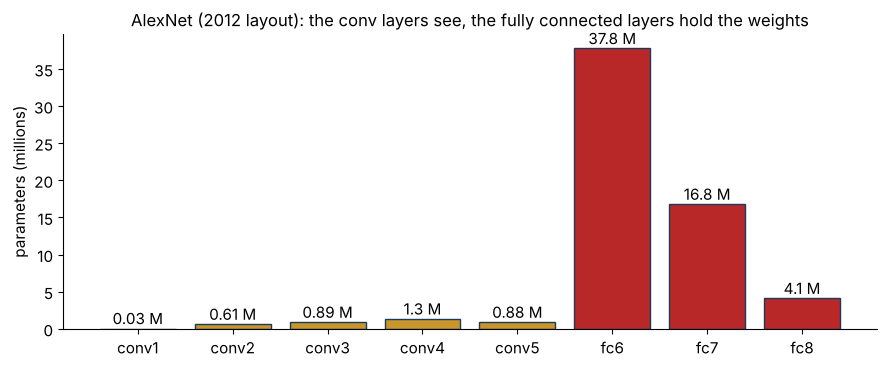

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
nm = [n for n, _ in rows]; pm = np.array([p for _, p in rows]) / 1e6
ax.bar(nm, pm, color=[GOLD] * 5 + [RED] * 3, edgecolor=NAVY)
for i, v in enumerate(pm):
    ax.text(i, v + 0.6, f"{v:.2f} M" if v < 1 else f"{v:.1f} M", ha="center", fontsize=11)
ax.set_ylabel("parameters (millions)")
ax.set_title("AlexNet (2012 layout): the conv layers see, the fully connected layers hold the weights", fontsize=12)
plt.tight_layout(); plt.show()

The five conv layers, which do all the looking at the image, hold **6%** of the weights.
**fc6 alone holds 61%.** Large fully connected layers are expensive and easy to over-fit,
which is why AlexNet needed **dropout** (randomly switching off half the fc neurons while
training) and **data augmentation** (random crops and flips; L14). ResNet replaces them (§11).

Other things that made AlexNet work in 2012: the **ReLU** (it trained about six times faster
than the S-shaped tanh used before), **two GPUs** (about a week of training) and **1.2 million
labelled photos** (ImageNet).

## 3 · VGG: stacked 3 × 3 filters and the receptive field

VGG (Simonyan & Zisserman, 2014) asked one question: what if every conv layer is **3 × 3**,
and we just stack more of them?

The **receptive field** of a neuron is the patch of the input image that can affect it.
One 3 × 3 layer sees 3 × 3 pixels. A second 3 × 3 layer on top sees 3 × 3 of the first
layer's outputs, each of which saw 3 × 3 pixels: **5 × 5** in total. Each extra 3 × 3 layer
(stride 1) adds 2:

$$\text{receptive field after } n \text{ layers} = 2n + 1$$

We can **check** this with backprop: ask which input pixels change the centre output. Their
gradient is non-zero; every other pixel's gradient is exactly 0.

In [8]:
def receptive_field_check(n_layers, size=21):
    torch.manual_seed(0)
    net = nn.Sequential(*[nn.Conv2d(1, 1, 3, padding=1) for _ in range(n_layers)])
    with torch.no_grad():                       # all-positive weights so nothing cancels by chance
        for m in net: m.weight.uniform_(0.1, 1.0)
    img = torch.zeros(1, 1, size, size, requires_grad=True)
    net(img)[0, 0, size // 2, size // 2].backward()      # one output pixel, the centre
    nz = (img.grad[0, 0].abs() > 0).numpy()
    rows, cols = np.where(nz)
    return int(rows.max() - rows.min() + 1), int(cols.max() - cols.min() + 1)

for n in (1, 2, 3, 5):
    print(f"{n} layer(s) of 3x3: the centre output depends on a {receptive_field_check(n)} patch "
          f"(formula 2n+1 = {2*n+1})")

1 layer(s) of 3x3: the centre output depends on a (3, 3) patch (formula 2n+1 = 3)
2 layer(s) of 3x3: the centre output depends on a (5, 5) patch (formula 2n+1 = 5)
3 layer(s) of 3x3: the centre output depends on a (7, 7) patch (formula 2n+1 = 7)
5 layer(s) of 3x3: the centre output depends on a (11, 11) patch (formula 2n+1 = 11)


**Why stack small filters instead of using one big one?** Same view, fewer weights, more
bends. With *C* channels in and out (biases ignored):

| | sees | weights |
|---|---|---|
| one 5 × 5 layer | 5 × 5 | 25 *C*² |
| two 3 × 3 layers | 5 × 5 | 2 × 9 *C*² = 18 *C*² |
| one 7 × 7 layer | 7 × 7 | 49 *C*² |
| three 3 × 3 layers | 7 × 7 | 3 × 9 *C*² = 27 *C*² |

And three layers have three ReLUs between them instead of one: more bends, so more they can
represent (L12, slide 9).

In [9]:
C = 64
one7  = nn.Conv2d(C, C, 7, padding=3, bias=False)
three3 = nn.Sequential(*[nn.Conv2d(C, C, 3, padding=1, bias=False) for _ in range(3)])
print(f"one 7x7, 64 -> 64 channels   : {n_params(one7):,d} weights  (49 x 64 x 64)")
print(f"three 3x3, 64 -> 64 channels : {n_params(three3):,d} weights  (27 x 64 x 64)  "
      f"= {n_params(three3)/n_params(one7):.0%} of the 7x7")

one 7x7, 64 -> 64 channels   : 200,704 weights  (49 x 64 x 64)
three 3x3, 64 -> 64 channels : 110,592 weights  (27 x 64 x 64)  = 55% of the 7x7


## 4 · VGG-16 shapes

VGG-16 is five **blocks**. Inside a block, every conv is 3 × 3 with padding 1, so the size is
kept (L12: (n + 2 − 3)/1 + 1 = n). Each block ends with a 2 × 2 max-pool that **halves** the
size, and the next block **doubles** the channels (64 → 128 → 256 → 512, then 512 again).

224 → 112 → 56 → 28 → 14 → 7: five halvings, 224 / 2⁵ = 7.

In [10]:
vgg = zoo["VGG-16"]
x = torch.zeros(1, 3, 224, 224)
block, convs = 1, 0
with torch.no_grad():
    for layer in vgg.features:
        x = layer(x)
        if isinstance(layer, nn.Conv2d): convs += 1
        if isinstance(layer, nn.MaxPool2d):
            print(f"block {block}: {convs} conv layers, then pool -> {x.shape[2]} x {x.shape[3]} x {x.shape[1]}")
            block += 1; convs = 0
fc6 = vgg.classifier[0]
print(f"\nflatten: 7 x 7 x 512 = {7*7*512:,d} numbers")
print(f"fc6: {fc6.in_features:,d} x {fc6.out_features:,d} + {fc6.out_features:,d} = {n_params(fc6):,d} parameters "
      f"({n_params(fc6)/n_params(vgg):.0%} of VGG-16's {n_params(vgg):,d})")

block 1: 2 conv layers, then pool -> 112 x 112 x 64
block 2: 2 conv layers, then pool -> 56 x 56 x 128
block 3: 3 conv layers, then pool -> 28 x 28 x 256


block 4: 3 conv layers, then pool -> 14 x 14 x 512
block 5: 3 conv layers, then pool -> 7 x 7 x 512

flatten: 7 x 7 x 512 = 25,088 numbers
fc6: 25,088 x 4,096 + 4,096 = 102,764,544 parameters (74% of VGG-16's 138,357,544)


## 5 · What one neuron sees, on a 1958 frame

Pooling makes the receptive field grow faster: after a stride-2 pool, each step of the next
layer moves 2 input pixels, so a 3 × 3 conv there adds 4, not 2. The rule, layer by layer:

- receptive field *r* ← *r* + (*k* − 1) × *j*
- jump *j* ← *j* × *s* (how many input pixels one step at this layer covers)

starting from *r* = 1, *j* = 1. Below: the receptive field at the end of each VGG-16 block,
drawn on frame 16046-19.

In [11]:
r, j, ends = 1, 1, []
blk, conv_in_blk = 1, 0
for layer in vgg.features:
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d)):
        k = layer.kernel_size if isinstance(layer.kernel_size, int) else layer.kernel_size[0]
        s = layer.stride if isinstance(layer.stride, int) else layer.stride[0]
        if isinstance(layer, nn.Conv2d):
            conv_in_blk += 1
            r += (k - 1) * j
            last = (f"conv{blk}_{conv_in_blk}", r)
        else:
            ends.append(last)
            r += (k - 1) * j; j *= s
            blk += 1; conv_in_blk = 0
print("receptive field at the last conv of each block:")
for nm, rf in ends: print(f"  {nm}: {rf} x {rf} pixels")
print(f"after the final pool: {r} x {r} pixels")

receptive field at the last conv of each block:
  conv1_2: 5 x 5 pixels
  conv2_2: 14 x 14 pixels
  conv3_3: 40 x 40 pixels
  conv4_3: 92 x 92 pixels
  conv5_3: 196 x 196 pixels
after the final pool: 212 x 212 pixels


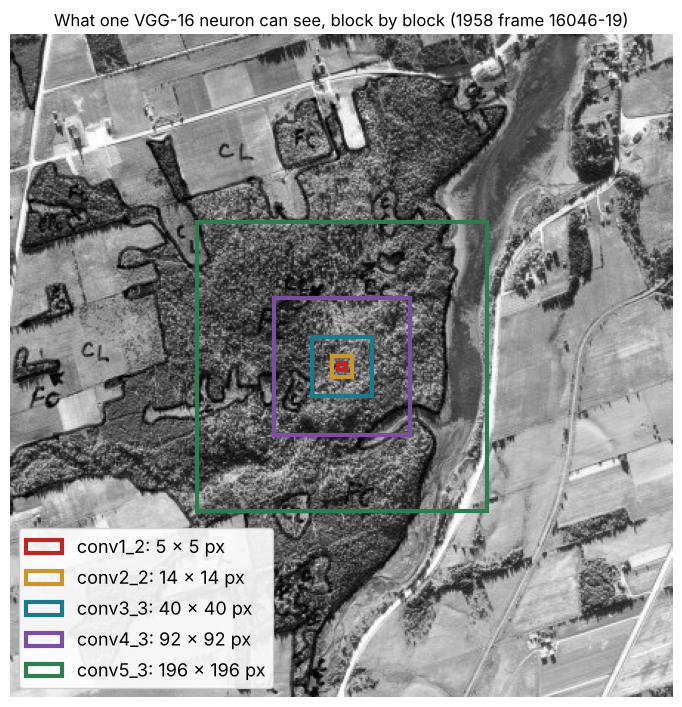

In [12]:
S = 448
cy, cx = 470, 500                                   # woodland, fields and a stream
view = frame[cy - S // 2: cy + S // 2, cx - S // 2: cx + S // 2]
fig, ax = plt.subplots(figsize=(7.2, 7.2))
ax.imshow(view, cmap="gray"); ax.axis("off")
for (nm, rf), col in zip(ends, (RED, GOLD, TEAL, PURPLE, GREEN)):
    ax.add_patch(plt.Rectangle((S / 2 - rf / 2, S / 2 - rf / 2), rf, rf, fill=False, ec=col, lw=3,
                               label=f"{nm}: {rf} × {rf} px"))
ax.legend(loc="lower left", fontsize=13, framealpha=0.9)
ax.set_title("What one VGG-16 neuron can see, block by block (1958 frame 16046-19)", fontsize=12)
plt.tight_layout(); plt.show()

Early neurons see a few pixels: an edge, a speck of texture (L4–L6 territory). By block 5 a
single neuron sees almost 200 × 200 pixels: a whole woodlot and the edges of the fields around it. Depth is how a
CNN gets from edges to objects.

## 6 · Deeper is not automatically better

If depth helps, why stop at 19 layers? Let's test it on the digits. The network below is L12's
CNN with a different shape: a first conv layer, then a stack of **blocks** (two 3 × 3 convs
each, 16 channels, padding 1), then an average over the 8 × 8 map (§11) and one fully
connected layer. The same class can switch on **batch norm** (§9) and a **skip connection**
(§8), so we can compare like with like.

We train a **5-layer** and a **31-layer** version (conv layers counted), with the same optimiser,
learning rate and 30 epochs, and watch the **training** loss.

In [13]:
class Block(nn.Module):
    # two 3x3 convs; optional batch norm after each, optional skip connection around both
    def __init__(self, C, bn=False, skip=False):
        super().__init__()
        self.skip = skip
        self.conv1 = nn.Conv2d(C, C, 3, padding=1, bias=not bn)   # with batch norm the bias is redundant (beta does it)
        self.conv2 = nn.Conv2d(C, C, 3, padding=1, bias=not bn)
        self.bn1 = nn.BatchNorm2d(C) if bn else nn.Identity()
        self.bn2 = nn.BatchNorm2d(C) if bn else nn.Identity()

    def forward(self, x):
        h = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))   # F(x)
        return F.relu(x + h) if self.skip else F.relu(h)            # ResNet: x + F(x)

class DigitNet(nn.Module):
    def __init__(self, n_conv, C=16, bn=False, skip=False):
        super().__init__()
        self.stem = nn.Conv2d(1, C, 3, padding=1)
        self.blocks = nn.Sequential(*[Block(C, bn, skip) for _ in range((n_conv - 1) // 2)])
        self.fc = nn.Linear(C, 10)

    def forward(self, x):
        x = self.blocks(F.relu(self.stem(x)))
        return self.fc(x.mean(dim=(2, 3)))          # global average pooling, then 10 scores

def train(model, epochs=30, lr=0.003):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(xtr_t)); total = 0.0
        for i in range(0, len(xtr_t), 32):
            idx = perm[i:i + 32]
            loss = F.cross_entropy(model(xtr_t[idx]), ytr_t[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            acc = float((model(xte_t).argmax(1).numpy() == yte).mean())
        hist.append((total / len(xtr_t), acc))
    return np.array(hist)

def run(label, **kw):
    torch.manual_seed(0)
    m = DigitNet(**kw); t0 = time.time()
    h = train(m)
    print(f"{label:28s} params {n_params(m):7,d}   final training loss {h[-1, 0]:.3f}   "
          f"test accuracy {h[-1, 1]:.1%}   ({time.time() - t0:.0f} s)")
    return h

results = {}
results["plain, 5 layers"] = run("plain, 5 layers", n_conv=5)
results["plain, 31 layers"] = run("plain, 31 layers", n_conv=31)

plain, 5 layers              params   9,610   final training loss 0.121   test accuracy 93.7%   (6 s)


plain, 31 layers             params  69,930   final training loss 2.303   test accuracy 10.2%   (25 s)


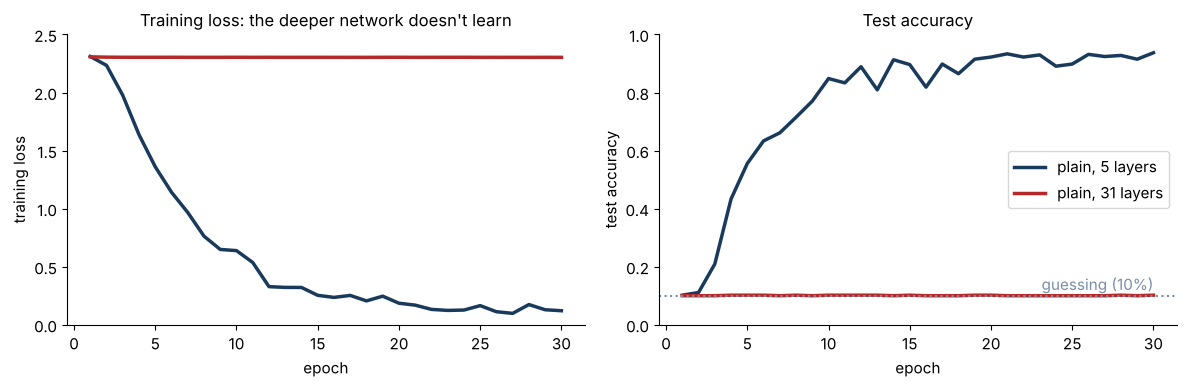

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, col in (("plain, 5 layers", NAVY), ("plain, 31 layers", RED)):
    h = results[lab]
    ax[0].plot(range(1, 31), h[:, 0], color=col, lw=2.5, label=lab)
    ax[1].plot(range(1, 31), h[:, 1], color=col, lw=2.5, label=lab)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_ylim(0, 2.5)
ax[0].set_title("Training loss: the deeper network doesn't learn", fontsize=12)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy"); ax[1].set_ylim(0, 1)
ax[1].axhline(0.1, color=GREY, ls=":"); ax[1].text(30, 0.12, "guessing (10%)", ha="right", color=GREY)
ax[1].set_title("Test accuracy", fontsize=12); ax[1].legend(loc="center right")
plt.tight_layout(); plt.show()

The 31-layer network is stuck at a loss of 2.30 = −ln(1/10): it is guessing. It is not
**over-fitting** (that would be a low training loss and a poor test score); it can't even fit
the **training** data. The 31-layer network could copy the 5-layer one and make its extra
layers do nothing, yet training never finds that.

The ResNet paper saw the same on CIFAR-10: a plain 56-layer network had **higher training
error** than a plain 20-layer one. (Their plain networks already had batch norm, so the effect
was milder than ours.)

## 7 · Why: the vanishing gradient

Backpropagation (L12) multiplies one local slope per layer on the way back from the loss.
If each layer's slope is about 0.5, then after 10 layers the slope reaching the first layer is
0.5¹⁰ ≈ 0.001, and after 30 layers about 10⁻⁹. The first layers get almost no signal, so
they barely change.

In [15]:
for n in (1, 5, 10, 20, 30):
    print(f"{n:2d} layers, slope 0.5 each: 0.5^{n} = {0.5**n:.1e}")

 1 layers, slope 0.5 each: 0.5^1 = 5.0e-01
 5 layers, slope 0.5 each: 0.5^5 = 3.1e-02
10 layers, slope 0.5 each: 0.5^10 = 9.8e-04
20 layers, slope 0.5 each: 0.5^20 = 9.5e-07
30 layers, slope 0.5 each: 0.5^30 = 9.3e-10


Here is the real thing: the size of the gradient on each conv layer's weights, for one batch
of 256 training digits, **before** any training. Plain 31-layer vs the same network with skip
connections (§8).

plain 31: layer 1 9.2e-16, layer 31 3.0e-04  -> ratio 3e+11
skip  31: layer 1 7.9e-04, layer 31 6.9e-04  -> ratio 1


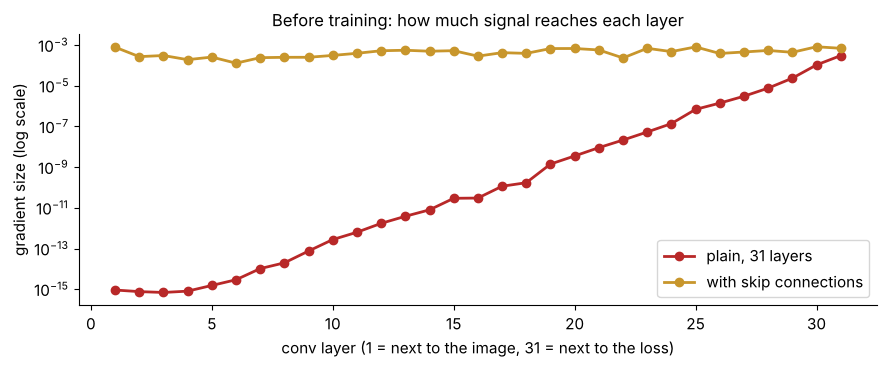

In [16]:
def grad_per_layer(model):
    model.train(); model.zero_grad()
    F.cross_entropy(model(xtr_t[:256]), ytr_t[:256]).backward()
    return np.array([m.weight.grad.pow(2).mean().sqrt().item()          # RMS gradient of the layer's weights
                     for m in model.modules() if isinstance(m, nn.Conv2d)])

torch.manual_seed(0); g_plain = grad_per_layer(DigitNet(31))
torch.manual_seed(0); g_skip = grad_per_layer(DigitNet(31, skip=True))
print(f"plain 31: layer 1 {g_plain[0]:.1e}, layer 31 {g_plain[-1]:.1e}  -> ratio {g_plain[-1]/g_plain[0]:.0e}")
print(f"skip  31: layer 1 {g_skip[0]:.1e}, layer 31 {g_skip[-1]:.1e}  -> ratio {g_skip[-1]/g_skip[0]:.0f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogy(range(1, 32), g_plain, "o-", color=RED, lw=2, label="plain, 31 layers")
ax.semilogy(range(1, 32), g_skip, "o-", color=GOLD, lw=2, label="with skip connections")
ax.set_xlabel("conv layer (1 = next to the image, 31 = next to the loss)")
ax.set_ylabel("gradient size (log scale)")
ax.set_title("Before training: how much signal reaches each layer", fontsize=12)
ax.legend(); plt.tight_layout(); plt.show()

## 8 · The skip connection by hand

A **residual block** adds its input back to its output: **y = x + F(x)**, where F is the block's
layers. Take the smallest possible F, one weight and a ReLU: F(x) = ReLU(w·x).

| | plain: y = ReLU(w·x) | residual: y = x + ReLU(w·x) |
|---|---|---|
| x = 2, w = −1 | y = 0, slope dy/dx = 0 | y = 2, slope = 1 |
| x = 3, w = 2 | y = 6, slope = 2 | y = 9, slope = 1 + 2 = 3 |

When F is "off", the plain block **destroys** both the signal and the gradient; the residual
block **passes the input straight through** with slope 1. So a residual block that isn't
useful can learn F ≈ 0 and do no harm, and the gradient always has a direct path back
(dy/dx = 1 + dF/dx).

In [17]:
for xv, wv in ((2.0, -1.0), (3.0, 2.0)):
    for kind in ("plain", "residual"):
        x = torch.tensor(xv, requires_grad=True); w = torch.tensor(wv)
        F_x = torch.relu(w * x)
        yv = F_x if kind == "plain" else x + F_x
        yv.backward()
        print(f"x = {xv:g}, w = {wv:g}, {kind:8s}: y = {yv.item():g}, dy/dx = {x.grad.item() + 0.0:g}")

x = 2, w = -1, plain   : y = 0, dy/dx = 0
x = 2, w = -1, residual: y = 2, dy/dx = 1
x = 3, w = 2, plain   : y = 6, dy/dx = 2
x = 3, w = 2, residual: y = 9, dy/dx = 3


## 9 · Batch normalisation by hand

**Batch normalisation** (Ioffe & Szegedy, 2015) re-centres and re-scales each channel, using
the numbers in the current mini-batch, so the next layer always sees values of a similar size:

1. subtract the batch mean, divide by the batch standard deviation (like centring before PCA in L9),
2. multiply by a learned **γ** and add a learned **β**, so the network can undo it if that helps.

By hand: one channel, a batch of five values **7, 9, 10, 11, 13**.
Mean 10; deviations −3, −1, 0, 1, 3; variance (9 + 1 + 0 + 1 + 9)/5 = 4; std 2.
Normalised: **−1.5, −0.5, 0, 0.5, 1.5**. With γ = 2, β = 1: **−2, 0, 1, 2, 4**.

Batch norm has **2 parameters per channel** (γ and β). At test time it uses running averages of
the mean and std collected during training, not the test batch.

In [18]:
v = np.array([7, 9, 10, 11, 13], np.float32)
z = (v - v.mean()) / v.std()                     # np.std divides by n, as batch norm does
print("mean", v.mean(), " std", v.std(), " normalised", z, " gamma=2, beta=1:", 2 * z + 1)

bn = nn.BatchNorm1d(1)                            # one channel
with torch.no_grad(): bn.weight.fill_(2.0); bn.bias.fill_(1.0)
bn.train()
print("PyTorch BatchNorm1d:", bn(torch.tensor(v)[:, None]).detach().numpy().ravel().round(3),
      f"  parameters: {n_params(bn)} (gamma, beta)")

mean 10.0  std 2.0  normalised [-1.5 -0.5  0.   0.5  1.5]  gamma=2, beta=1: [-2.  0.  1.  2.  4.]
PyTorch BatchNorm1d: [-2.  0.  1.  2.  4.]   parameters: 2 (gamma, beta)


## 10 · Fixing depth: batch norm and skip connections

Same 31 layers, same training, three fixes: batch norm only, skip connections only, and both
(which is what ResNet does).

In [19]:
results["31 + batch norm"] = run("31 + batch norm", n_conv=31, bn=True)
results["31 + skip"] = run("31 + skip", n_conv=31, skip=True)
results["31 + both (ResNet)"] = run("31 + both (ResNet)", n_conv=31, bn=True, skip=True)

31 + batch norm              params  70,410   final training loss 0.143   test accuracy 96.7%   (29 s)


31 + skip                    params  69,930   final training loss 0.000   test accuracy 96.7%   (25 s)


31 + both (ResNet)           params  70,410   final training loss 0.016   test accuracy 99.4%   (33 s)


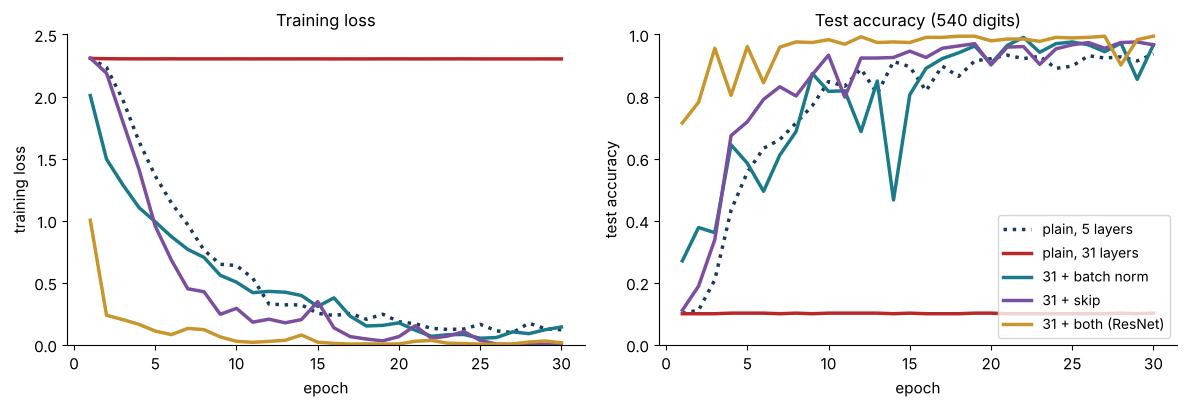

                       train loss  test acc
plain, 5 layers             0.121     93.7%
plain, 31 layers            2.303     10.2%
31 + batch norm             0.143     96.7%
31 + skip                   0.000     96.7%
31 + both (ResNet)          0.016     99.4%


In [20]:
styles = {"plain, 5 layers": (NAVY, ":"), "plain, 31 layers": (RED, "-"), "31 + batch norm": (TEAL, "-"),
          "31 + skip": (PURPLE, "-"), "31 + both (ResNet)": (GOLD, "-")}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for lab, (col, ls) in styles.items():
    h = results[lab]
    ax[0].plot(range(1, 31), h[:, 0], color=col, ls=ls, lw=2.5, label=lab)
    ax[1].plot(range(1, 31), h[:, 1], color=col, ls=ls, lw=2.5, label=lab)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_ylim(0, 2.5)
ax[0].set_title("Training loss", fontsize=12)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy"); ax[1].set_ylim(0, 1)
ax[1].set_title("Test accuracy (540 digits)", fontsize=12); ax[1].legend(loc="lower right", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'':22s} {'train loss':>10s} {'test acc':>9s}")
for lab, h in results.items():
    print(f"{lab:22s} {h[-1, 0]:10.3f} {h[-1, 1]:9.1%}")

Either fix alone rescues the 31-layer network. With both, the training loss drops fastest.
On 8 × 8 digits a 5-layer network is already enough, so depth buys little here. On ImageNet
photos the same two fixes let ResNet go to 152 layers and beat every shallower network.

(One seed. We also ran seeds 1 and 2: the plain 31-layer network stayed at chance every time,
and every fixed version trained, with final test accuracy between 90% and 99%. The last-epoch
number jumps around by a few points, so don't read much into the order of the three fixes.
Try it: change `torch.manual_seed(0)` in `run`.)

## 11 · ResNet-18 shapes and global average pooling

ResNet uses VGG's 3 × 3 convs, wrapped in residual blocks (conv → batch norm → ReLU → conv →
batch norm, + x, ReLU), and halves the size with stride-2 convs between stages.

At the end there is **no big fully connected layer**. **Global average pooling** averages each
of the 512 final 7 × 7 maps to one number, then a single fully connected layer turns those 512
numbers into 1,000 class scores: 512 × 1,000 + 1,000 = **513,000** parameters, instead of
VGG's 102.8 million in fc6 alone.

In [21]:
r18 = zoo["ResNet-18"]
x = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    x = r18.maxpool(r18.relu(r18.bn1(r18.conv1(x))))
    print(f"stem (7x7 conv stride 2, pool)  -> {x.shape[2]} x {x.shape[3]} x {x.shape[1]}")
    for i, stage in enumerate((r18.layer1, r18.layer2, r18.layer3, r18.layer4), start=1):
        x = stage(x)
        print(f"stage {i} ({len(stage)} residual blocks)    -> {x.shape[2]} x {x.shape[3]} x {x.shape[1]}")
    x = r18.avgpool(x)
    print(f"global average pool             -> {x.shape[1]} numbers")
print(f"fc: {r18.fc.in_features} x {r18.fc.out_features} + {r18.fc.out_features} = {n_params(r18.fc):,d} parameters")

# global average pooling by hand: one 2 x 2 channel
m = torch.tensor([[1., 3.], [5., 7.]])[None, None]
print("GAP of [[1, 3], [5, 7]] =", F.adaptive_avg_pool2d(m, 1).item())

stem (7x7 conv stride 2, pool)  -> 56 x 56 x 64
stage 1 (2 residual blocks)    -> 56 x 56 x 64
stage 2 (2 residual blocks)    -> 28 x 28 x 128
stage 3 (2 residual blocks)    -> 14 x 14 x 256
stage 4 (2 residual blocks)    -> 7 x 7 x 512
global average pool             -> 512 numbers
fc: 512 x 1000 + 1000 = 513,000 parameters
GAP of [[1, 3], [5, 7]] = 4.0


## 12 · The three side by side

Top-5 error is the published ILSVRC result for each network's year (the share of test photos
where the right class is not among the network's top five guesses). AlexNet's 15.3% and
ResNet's 3.6% were winning entries; VGG's 7.3% came second in 2014 (GoogLeNet won with 6.7%).

In [22]:
table = [("AlexNet", 2012, zoo["AlexNet"], "15.3%", "big filters (11x11), 3 big fc layers"),
         ("VGG-16", 2014, zoo["VGG-16"], "7.3%", "only 3x3, deeper; still 3 big fc layers"),
         ("ResNet-152", 2015, zoo["ResNet-152"], "3.6%", "skip connections + batch norm; GAP")]
print(f"{'network':11s} {'year':>5s} {'layers':>7s} {'parameters':>12s} {'top-5 error':>12s}   idea")
for name, yr, m, err, idea in table:
    print(f"{name:11s} {yr:5d} {weight_layers(m):7d} {n_params(m)/1e6:10.1f} M {err:>12s}   {idea}")

network      year  layers   parameters  top-5 error   idea
AlexNet      2012       8       61.1 M        15.3%   big filters (11x11), 3 big fc layers
VGG-16       2014      16      138.4 M         7.3%   only 3x3, deeper; still 3 big fc layers
ResNet-152   2015     152       60.2 M         3.6%   skip connections + batch norm; GAP


## 13 · Try at home

**A. Count by hand, then check.** VGG's first layer: 64 filters, 3 × 3, padding 1, on a 224 × 224
RGB image. Output shape? Parameters? Check with `n_params(nn.Conv2d(3, 64, 3, padding=1))`.

**B. Even deeper.** In §6 and §10, try `n_conv=51`. Which versions still train?

**C. Receptive field of ResNet-18.** Adapt the §5 loop to `zoo["ResNet-18"]` (the convs are inside
`layer1` … `layer4`; use `r18.modules()`). Hint: the stem alone (7 × 7 stride 2, then a 3 × 3
stride-2 pool) already gives 11 × 11.

**D. What did AlexNet learn? (Colab, needs a download.)** Load the **trained** weights and look at
the 64 first-layer filters. Compare them with L4's edge filters and L12's learned Sobel.

```python
alex = torchvision.models.alexnet(weights="DEFAULT")       # downloads about 230 MB
w = alex.features[0].weight.detach()                       # 64 x 3 x 11 x 11
w = (w - w.min()) / (w.max() - w.min())
fig, ax = plt.subplots(4, 16, figsize=(16, 4.4))
for a, f in zip(ax.ravel(), w):
    a.imshow(f.permute(1, 2, 0)); a.axis("off")
plt.show()
```

Next: **AL7** (Friday) — train your own CNN on CIFAR-10 (try adding batch norm). **L14** (Monday)
— transfer learning: start from a ResNet someone else trained on ImageNet.